In [1]:
import ee

In [2]:
import geemap

In [3]:
import folium

In [4]:
import numpy as np

In [5]:
import pandas as pd

In [6]:
import matplotlib.pyplot as plt

In [7]:
from IPython.display import display

In [8]:
ee.Authenticate()

True

In [9]:
ee.Initialize()

In [10]:
asset_path = 'projects/booming-skill-496914-d5/assets/Palamu_AOI'
Palamu_AOI = ee.FeatureCollection(asset_path)
print("Palamu AOI loaded")

Palamu AOI loaded


In [11]:
modis_ndvi = ee.ImageCollection("MODIS/061/MOD13Q1").select('NDVI').filterBounds(Palamu_AOI)

In [12]:
historical_data = modis_ndvi.filterDate('2010-01-01', '2026-01-01')

In [13]:
ndvi_min = historical_data.min().clip(Palamu_AOI)
ndvi_max = historical_data.max().clip(Palamu_AOI)

In [14]:
current_ndvi = modis_ndvi.filterDate('2025-06-01', '2025-10-31').mean().clip(Palamu_AOI)
print("NDVI Min, Max and Current NDVI Calculated")

NDVI Min, Max and Current NDVI Calculated


In [15]:
vci = current_ndvi.subtract(ndvi_min).divide(ndvi_max.subtract(ndvi_min))

In [16]:
vci = vci.clamp(0, 1)
print("15 years of time-series data")

15 years of time-series data


In [17]:
years = ee.List.sequence(2010,2025)

In [18]:
def get_yearly_ndvi(year):
    start = ee.Date.fromYMD(year, 6, 1)
    end = ee.Date.fromYMD(year, 10, 31)
    
    mean_val = modis_ndvi.filterDate(start, end).mean().reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=Palamu_AOI,
        scale=250,
        maxPixels=1e9
    ).get('NDVI')
    
    return ee.Feature(None, {'Year': year, 'Mean_NDVI': mean_val})

In [19]:
yearly_data = ee.FeatureCollection(years.map(get_yearly_ndvi))
data_list = yearly_data.reduceColumns(ee.Reducer.toList(2), ['Year', 'Mean_NDVI']).get('list').getInfo()

In [20]:
df = pd.DataFrame(data_list, columns = ['Year', 'Mean_NDVI'])

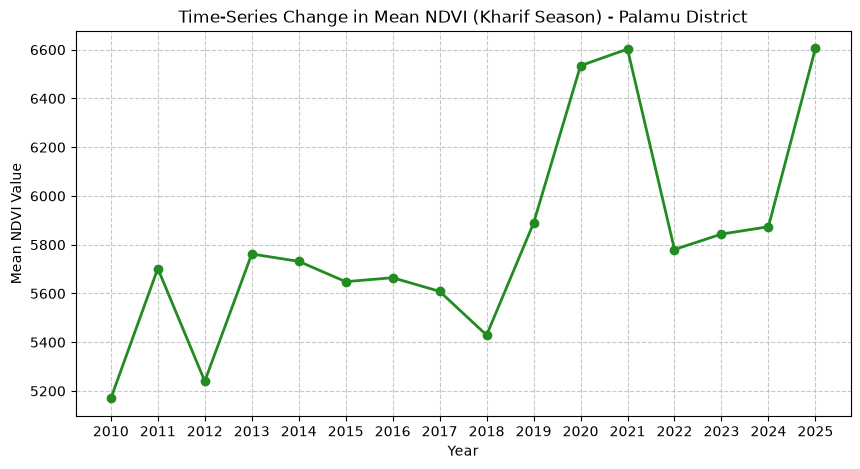

VCI Calculated & Time-Series Graph Generated


In [21]:
plt.figure(figsize=(10, 5))
plt.plot(df['Year'].astype(int).astype(str), df['Mean_NDVI'], marker='o', color='forestgreen', linewidth=2, markersize=6)
plt.title("Time-Series Change in Mean NDVI (Kharif Season) - Palamu District")
plt.xlabel("Year")
plt.ylabel("Mean NDVI Value")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

print("VCI Calculated & Time-Series Graph Generated")

In [22]:
drought_class = ee.Image(0) \
    .where(vci.lt(0.2), 1) \
    .where(vci.gte(0.2).And(vci.lt(0.4)), 2) \
    .where(vci.gte(0.4).And(vci.lt(0.6)), 3) \
    .where(vci.gte(0.6), 4) \
    .clip(Palamu_AOI)

In [23]:
drought_class = drought_class.focal_mode(radius=1, kernelType='square', units='pixels')
print("Drought Classification and Smoothing Complete")

Drought Classification and Smoothing Complete


In [24]:
def add_ee_layer(self, ee_image_object, vis_params, name):
    map_id_dict = ee.Image(ee_image_object).getMapId(vis_params)
    folium.raster_layers.TileLayer(
        tiles=map_id_dict['tile_fetcher'].url_format,
        attr='Google Earth Engine',
        name=name,
        overlay=True,
        control=True
    ).add_to(self)
    
folium.Map.add_ee_layer = add_ee_layer

In [25]:
empty = ee.Image().byte()
boundary = empty.paint(featureCollection=Palamu_AOI, color=1, width=2)

In [26]:
area_image = ee.Image.pixelArea().addBands(drought_class)

In [27]:
stats = area_image.reduceRegion(
    reducer=ee.Reducer.sum().group(groupField=1, groupName='class'),
    geometry=Palamu_AOI,
    scale=250,  
    maxPixels=1e10
).getInfo()

In [28]:
print(" Drought Area Statistics ")
class_names = {1: "Extreme Drought", 2: "Moderate Drought", 3: "Mild Drought", 4: "Normal"}
for item in stats['groups']:
    class_id = item['class']
    area_sqkm = item['sum'] / 1000000 
    print(f"{class_names.get(class_id, 'Unknown')}: {area_sqkm:.2f} Sq Km")

 Drought Area Statistics 
Moderate Drought: 6.15 Sq Km
Mild Drought: 168.87 Sq Km
Normal: 4242.20 Sq Km


In [29]:
print("MAP 1: Current Year NDVI (Vegetation Greenness)")
map1 = folium.Map(location=[24.0, 84.1], zoom_start=9)
ndvi_vis = {'min': 0, 'max': 1, 'palette': ['white', 'lightgreen', 'darkgreen']}
map1.add_ee_layer(current_ndvi, ndvi_vis, 'Current NDVI')
map1.add_ee_layer(boundary, {'palette': ['black']}, 'Palamu Boundary')
display(map1)

MAP 1: Current Year NDVI (Vegetation Greenness)


In [30]:
print("MAP 2: VCI Raster Map (Drought Condition)")
map2 = folium.Map(location=[24.0, 84.1], zoom_start=9)
vci_vis = {'min': 0, 'max': 1, 'palette': ['red', 'yellow', 'green']}
map2.add_ee_layer(vci, vci_vis, 'VCI Map')
map2.add_ee_layer(boundary, {'palette': ['black']}, 'Palamu Boundary')
display(map2)

MAP 2: VCI Raster Map (Drought Condition)


In [31]:
print("MAP 3: Classified Drought Severity Zones")
map3 = folium.Map(location=[24.0, 84.1], zoom_start=9)
class_vis = {'min': 1, 'max': 4, 'palette': ['red', 'orange', 'yellow', 'green']}
map3.add_ee_layer(drought_class, class_vis, 'Drought Severity Map')
map3.add_ee_layer(boundary, {'palette': ['black']}, 'Palamu Boundary')
display(map3)

MAP 3: Classified Drought Severity Zones


In [32]:
Map = geemap.Map()
Map.centerObject(Palamu_AOI, 9)